In [1]:
# Mengimpor seluruh pustaka yang dibutuhkan
import os
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("Pustaka preprocessing berhasil dimuat.")

Pustaka preprocessing berhasil dimuat.


In [2]:
# Memuat data cafe dan data ulasan dari direktori dataset
df_cafes = pd.read_csv('../dataset/cafes.csv')
df_reviews = pd.read_csv('../dataset/reviews.csv')

print(f"Data Cafes loaded   : {df_cafes.shape[0]} baris, {df_cafes.shape[1]} kolom")
print(f"Data Reviews loaded : {df_reviews.shape[0]} baris, {df_reviews.shape[1]} kolom")

Data Cafes loaded   : 275 baris, 18 kolom
Data Reviews loaded : 7736 baris, 10 kolom


In [3]:
# Pemeriksaan informasi tipe data dan statistik lima angka (five-number summary)
print("=== INFORMASI DATASET CAFES ===")
print(df_cafes.info())

print("\n=== STATISTIK DESKRIPTIF FITUR NUMERIK CAFES ===")
num_cols_cafe = ['rating', 'review_count', 'price_min', 'price_max']
print(df_cafes[num_cols_cafe].describe())

print("\n=== SEBARAN KATEGORI CAFE (TOP 5) ===")
print(df_cafes['categories'].value_counts().head(5))

=== INFORMASI DATASET CAFES ===
<class 'pandas.DataFrame'>
RangeIndex: 275 entries, 0 to 274
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             275 non-null    str    
 1   place_id       0 non-null      float64
 2   name           275 non-null    str    
 3   address        275 non-null    str    
 4   latitude       275 non-null    float64
 5   longitude      275 non-null    float64
 6   rating         275 non-null    float64
 7   review_count   275 non-null    int64  
 8   image_url      0 non-null      float64
 9   categories     275 non-null    str    
 10  phone          203 non-null    str    
 11  website        109 non-null    str    
 12  created_at     275 non-null    str    
 13  updated_at     275 non-null    str    
 14  price_range    239 non-null    str    
 15  price_min      239 non-null    float64
 16  price_max      239 non-null    float64
 17  opening_hours  269 non-null    st

<string>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



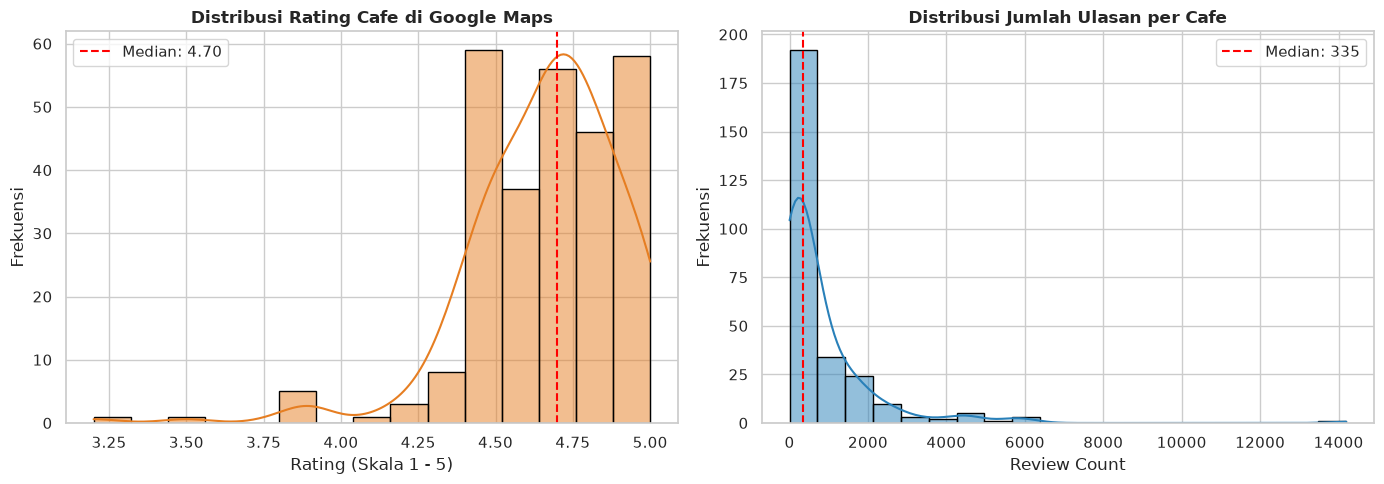

In [4]:
# Histogram distribusi Rating dan Jumlah Ulasan Cafe
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_cafes['rating'], bins=15, kde=True, color='#e67e22', edgecolor='black')
plt.axvline(df_cafes['rating'].median(), color='red', linestyle='--', label=f'Median: {df_cafes["rating"].median():.2f}')
plt.title('Distribusi Rating Cafe di Google Maps', fontsize=12, fontweight='bold')
plt.xlabel('Rating (Skala 1 - 5)')
plt.ylabel('Frekuensi')
plt.legend()

plt.subplot(1, 2, 2)
sns.histplot(df_cafes['review_count'], bins=20, kde=True, color='#2980b9', edgecolor='black')
plt.axvline(df_cafes['review_count'].median(), color='red', linestyle='--', label=f'Median: {df_cafes["review_count"].median():.0f}')
plt.title('Distribusi Jumlah Ulasan per Cafe', fontsize=12, fontweight='bold')
plt.xlabel('Review Count')
plt.ylabel('Frekuensi')
plt.legend()

plt.tight_layout()
plt.show()

In [5]:
# Pengecekan missing values sebelum imputasi
print("Jumlah missing values sebelum imputasi:")
print(df_cafes[['price_min', 'price_max', 'price_range', 'opening_hours']].isnull().sum())

# Menghitung median harga per kategori
median_min_global = df_cafes['price_min'].median()
median_max_global = df_cafes['price_max'].median()

# Imputasi harga minimum dan maksimum
df_cafes['price_min_imputed'] = df_cafes.groupby('categories')['price_min'].transform(lambda x: x.fillna(x.median()))
df_cafes['price_min_imputed'] = df_cafes['price_min_imputed'].fillna(median_min_global)

df_cafes['price_max_imputed'] = df_cafes.groupby('categories')['price_max'].transform(lambda x: x.fillna(x.median()))
df_cafes['price_max_imputed'] = df_cafes['price_max_imputed'].fillna(median_max_global)

# Imputasi opening hours
df_cafes['opening_hours_imputed'] = df_cafes['opening_hours'].fillna('Informasi Jam Buka Tidak Tersedia')

print("\nJumlah missing values setelah imputasi:")
print(df_cafes[['price_min_imputed', 'price_max_imputed', 'opening_hours_imputed']].isnull().sum())
print(f"Median Harga Minimum Imputasi: Rp {df_cafes['price_min_imputed'].median():,.0f}")
print(f"Median Harga Maksimum Imputasi: Rp {df_cafes['price_max_imputed'].median():,.0f}")

Jumlah missing values sebelum imputasi:
price_min        36
price_max        36
price_range      36
opening_hours     6
dtype: int64

Jumlah missing values setelah imputasi:
price_min_imputed        0
price_max_imputed        0
opening_hours_imputed    0
dtype: int64
Median Harga Minimum Imputasi: Rp 25,000
Median Harga Maksimum Imputasi: Rp 25,000


In [6]:
# Label Encoding pada kategori cafe
le = LabelEncoder()
df_cafes['category_encoded'] = le.fit_transform(df_cafes['categories'])

print("Sampel Hasil Label Encoding Kategori:")
encoding_map = pd.DataFrame({'Kategori': le.classes_, 'Encoded_ID': range(len(le.classes_))})
print(encoding_map.head(6).to_string(index=False))

# One-Hot Encoding pada kategori cafe
top_categories = df_cafes['categories'].value_counts().nlargest(4).index.tolist()
for cat in top_categories:
    clean_col_name = 'cat_' + re.sub(r'\W+', '_', cat.lower()).strip('_')
    df_cafes[clean_col_name] = (df_cafes['categories'] == cat).astype(int)

print("\nKolom hasil One-Hot Encoding kategori teratas:")
ohe_cols = [c for c in df_cafes.columns if c.startswith('cat_')]
print(df_cafes[['name'] + ohe_cols].head(4).to_string(index=False))

Sampel Hasil Label Encoding Kategori:
                                                    Kategori  Encoded_ID
                                       {"Bar Kopi Espresso"}           0
                                              {"Bar lounge"}           1
      {"Grosir Kopi","Kopi Enak",Keluarga,Affordable,Santai}           2
                                          {"Kafe anak-anak"}           3
                                               {"Kafe seni"}           4
{"Kedai Kopi","Kopi Enak",Affordable,Santai,WFC,"Fast Wifi"}           5

Kolom hasil One-Hot Encoding kategori teratas:
                                      name  cat_kedai_kopi  cat_kafe  cat_restoran  cat_kedai_kopi_santai_kopi_enak_estetik_wfc
Warkop DKI Lagi "Spesialis Pancong Balap "               0         1             0                                            0
        Warkop DKI "Spesial Pancong Balap"               1         0             0                                            0
                   

In [7]:
# Menerapkan StandardScaler dan MinMaxScaler
fitur_numerik = ['rating', 'review_count', 'price_min_imputed', 'price_max_imputed']

scaler_std = StandardScaler()
scaled_std = scaler_std.fit_transform(df_cafes[fitur_numerik])
df_scaled_std = pd.DataFrame(scaled_std, columns=[f'{c}_std' for c in fitur_numerik])

scaler_minmax = MinMaxScaler()
scaled_minmax = scaler_minmax.fit_transform(df_cafes[fitur_numerik])
df_scaled_minmax = pd.DataFrame(scaled_minmax, columns=[f'{c}_minmax' for c in fitur_numerik])

# Menggabungkan hasil scaling ke DataFrame cafe
df_cafes_processed = pd.concat([df_cafes, df_scaled_std, df_scaled_minmax], axis=1)

print("Perbandingan Statistik Fitur Sebelum dan Sesudah StandardScaler:")
print(df_scaled_std.describe().round(3).loc[['mean', 'std', 'min', 'max']])

Perbandingan Statistik Fitur Sebelum dan Sesudah StandardScaler:
      rating_std  ...  price_max_imputed_std
mean      -0.000  ...                  0.000
std        1.002  ...                  1.002
min       -5.886  ...                 -0.949
max        1.371  ...                  5.659

[4 rows x 4 columns]


In [8]:
# Fungsi pembersihan teks ulasan
def bersihkan_teks(teks):
    if not isinstance(teks, str):
        return ""
    # 1. Lowercase (case folding)
    teks = teks.lower()
    # 2. Hapus URL / tautan web
    teks = re.sub(r'https?://\S+|www\.\S+', '', teks)
    # 3. Hapus angka dan simbol khusus, sisakan huruf dan spasi
    teks = re.sub(r'[^a-zA-Z\s]', ' ', teks)
    # 4. Normalisasi spasi berlebih
    teks = re.sub(r'\s+', ' ', teks).strip()
    return teks

df_reviews['cleaned_text'] = df_reviews['text'].apply(bersihkan_teks)
df_reviews['char_length']  = df_reviews['cleaned_text'].apply(len)
df_reviews['word_count']   = df_reviews['cleaned_text'].apply(lambda x: len(x.split()))

print("Sampel Perbandingan Teks Sebelum vs Sesudah Pembersihan:")
for i in range(3):
    print(f"Ulasan Asli #{i+1} : {df_reviews['text'].iloc[i]}")
    print(f"Hasil Bersih  : {df_reviews['cleaned_text'].iloc[i]}")
    print(f"Statistik     : {df_reviews['word_count'].iloc[i]} kata, {df_reviews['char_length'].iloc[i]} karakter")
    print("-" * 60)

Sampel Perbandingan Teks Sebelum vs Sesudah Pembersihan:
Ulasan Asli #1 : Pengyu Kopitiam adalah salah satu kedai kopi modern berkonsep kopitiam vintage yang terletak di kawasan bersejarah Pertokoan Kayutangan, Malang. Kedai ini menyajikan aneka sajian peranakan dan Chinese food halal dengan harga yang relatif …
Hasil Bersih  : pengyu kopitiam adalah salah satu kedai kopi modern berkonsep kopitiam vintage yang terletak di kawasan bersejarah pertokoan kayutangan malang kedai ini menyajikan aneka sajian peranakan dan chinese food halal dengan harga yang relatif
Statistik     : 33 kata, 235 karakter
------------------------------------------------------------
Ulasan Asli #2 : makanannya oke tapi semuanya pake kuah kari yang agak teralu over
Hasil Bersih  : makanannya oke tapi semuanya pake kuah kari yang agak teralu over
Statistik     : 11 kata, 65 karakter
------------------------------------------------------------
Ulasan Asli #3 : sorry to say tp pelayanannya kureng sekali ya, terus ma

Korelasi terhadap Rating Cafe:
rating               1.000000
price_max_imputed    0.020664
price_min_imputed    0.004371
review_count        -0.099221
category_encoded    -0.201005
Name: rating, dtype: float64


<string>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



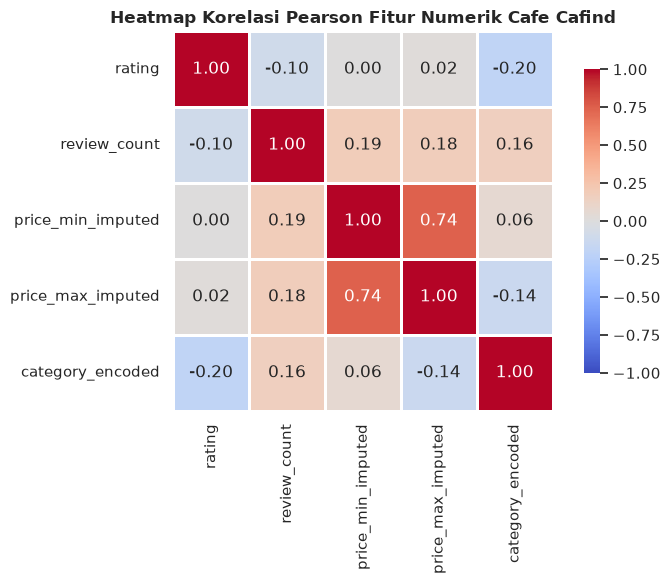

In [9]:
# Menghitung korelasi Pearson antar fitur numerik cafe
corr_features = ['rating', 'review_count', 'price_min_imputed', 'price_max_imputed', 'category_encoded']
corr_matrix = df_cafes_processed[corr_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1,
            linewidths=1, linecolor='white', square=True, cbar_kws={'shrink': .8})
plt.title('Heatmap Korelasi Pearson Fitur Numerik Cafe Cafind', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("Korelasi terhadap Rating Cafe:")
print(corr_matrix['rating'].sort_values(ascending=False))

In [10]:
# Menyimpan dataset yang telah dipreprocessing
os.makedirs('../outputs', exist_ok=True)

path_out_cafes   = '../outputs/cafes_preprocessed.csv'
path_out_reviews = '../outputs/reviews_preprocessed.csv'

df_cafes_processed.to_csv(path_out_cafes, index=False)
df_reviews.to_csv(path_out_reviews, index=False)

print(f"Tersimpan: {path_out_cafes} ({os.path.getsize(path_out_cafes):,} bytes)")
print(f"Tersimpan: {path_out_reviews} ({os.path.getsize(path_out_reviews):,} bytes)")

Tersimpan: ../outputs/cafes_preprocessed.csv (202,592 bytes)
Tersimpan: ../outputs/reviews_preprocessed.csv (3,712,884 bytes)
